<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Condition matches still need source scope

**Which condition matches belong in a scoped review, and which inputs lack usable
evidence?** We will use a small Sigma rule over twelve authored records, inspect its
metadata and referenced fields, audit JSON and field availability, then compare raw
condition matches with matches selected for the intended log source.

These are synthetic fixtures with no real accounts or machine logs. Source labels
are authored annotations, not authenticated provenance. A failed-logon-shaped event
is not evidence of an attack; this walkthrough demonstrates evaluation and data
coverage, not incident classification.

## Choose whether to enforce logsource labels

`ENFORCE_LOGSOURCE=True` requires the event's source product and service labels to
match the rule metadata before selecting a condition match. The experiment sets it
to `False` to expose how a broader scope changes the selected population. Raw worker
matches and field availability are unchanged. Restart and run all after editing.

In [1]:
ENFORCE_LOGSOURCE = True

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
from notebook_support import finish, prose, theme

if type(ENFORCE_LOGSOURCE) is not bool:
    raise ValueError("ENFORCE_LOGSOURCE must be True or False.")
coverage = summary = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sigma/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sigma/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sigma/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-sigma/notebooks/pyproject.toml.

## Attach the published worker and retain original records

The literal `uvx` command installs the worker from the immutable commit for release
v0.4.0. Runtime pins match the tested protocol and parser; no local worker checkout
is required. The JSONL file stores each inner event as a string, preserving malformed
JSON and NULL inputs for an explicit audit.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'sigma' (TYPE vgi,LOCATION 'uvx --python 3.14 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with pysigma==2.0.2 --from git+https://github.com/Query-farm/vgi-sigma@42390f68a4febac437403b2f48ada067f1c6fe23 vgi-sigma-worker');
CREATE TABLE inputs AS SELECT * FROM read_json('fixtures/events.jsonl',format='newline_delimited');
SELECT event_id,source_product,source_service,event_json FROM inputs ORDER BY event_id;

,event_id,source_product,source_service,event_json
0,array,windows,security,[]
1,empty-object,windows,security,{}
2,malformed,windows,security,{not-json
3,matched-a,windows,security,"{""EventID"":4625,""LogonType"":3}"
4,matched-b,windows,security,"{""EventID"":4625,""LogonType"":3}"
5,missing,windows,security,None
6,missing-field,windows,security,"{""EventID"":4625}"
7,null-field,windows,security,"{""EventID"":4625,""LogonType"":null}"
8,other-event,windows,security,"{""EventID"":4624,""LogonType"":3}"
9,other-logon,windows,security,"{""EventID"":4625,""LogonType"":2}"


## Validate the rule and inspect its declared scope

The rule selects an event with both `EventID: 4625` and `LogonType: 3`. It declares
Windows security logs as its intended source. The worker parses that metadata, but
`sigma_match` evaluates the condition tree against the supplied JSON; it does not
route events by `logsource`. SQL must enforce any required source selection.

We also retain an invalid rule's false validation result. Only the valid rule is
used for evaluation. Compilation checks supported rule syntax; it does not establish
that the rule is operationally useful.

In [4]:
%%sql
CREATE TABLE rules AS SELECT * FROM (VALUES
 ('selected',$rule$
title: Synthetic Failed Logon
status: experimental
level: low
logsource: {product: windows, service: security}
detection:
 selection:
  EventID: 4625
  LogonType: 3
 condition: selection
$rule$),('invalid','title: Incomplete rule')
) AS r(rule_id,rule_yaml);
CREATE TABLE rule_validation AS SELECT *,sigma.main.sigma_check(rule_yaml) AS compiles FROM rules;
SELECT rule_id,compiles,rule_yaml FROM rule_validation ORDER BY rule_id;

,rule_id,compiles,rule_yaml
0,invalid,False,title: Incomplete rule
1,selected,True,\ntitle: Synthetic Failed Logon\nstatus: exper...


In [5]:
assert con.execute("SELECT compiles FROM rule_validation WHERE rule_id='selected'").fetchone()[0]
# Table-function inputs must be constants; quote the exact source shown above.
rule_text = con.execute("SELECT rule_yaml FROM rules WHERE rule_id='selected'").fetchone()[0]
rule_sql = "'" + rule_text.replace("'", "''") + "'"

In [6]:
%%sql
CREATE TABLE rule_info AS SELECT * FROM sigma.main.sigma_rule_info({{ rule_sql }});
CREATE TABLE required_fields AS SELECT * FROM sigma.main.sigma_match_fields({{ rule_sql }});
SELECT title,status,level,product,service,tags FROM rule_info;

,title,status,level,product,service,tags
0,Synthetic Failed Logon,experimental,low,windows,security,[]


## Audit JSON shape and referenced-field availability

Malformed JSON and a valid JSON array both produce false from `sigma_match`. They
are different from valid object events that fail a condition. We preserve those
states with `try_cast` and `json_type` before interpreting the match result.

The worker supplies the rule's field list. For this flat, positive-AND rule, we can
show each field as present with a value, explicitly null, absent, or unavailable
because the input is not an object. This is a coverage audit, not another Sigma
evaluator. Rules using OR, NOT, null comparisons, or nested paths need different
coverage interpretation; missing one referenced field does not generally mean a
Sigma rule cannot match.

In [7]:
%%sql
CREATE TABLE parsed_inputs AS SELECT *,try_cast(event_json AS JSON) AS parsed FROM inputs;
CREATE TABLE input_quality AS SELECT *,CASE
 WHEN event_json IS NULL THEN 'Missing input'
 WHEN parsed IS NULL THEN 'Malformed JSON'
 WHEN json_type(parsed)<>'OBJECT' THEN 'Non-object JSON'
 ELSE 'Object' END AS input_kind
FROM parsed_inputs;
CREATE TABLE field_coverage AS SELECT i.event_id,i.input_kind,f.field,
 CASE WHEN i.input_kind<>'Object' THEN 'Unavailable'
 WHEN NOT json_exists(i.parsed,'$.'||f.field) THEN 'Absent'
 WHEN json_type(json_extract(i.parsed,'$.'||f.field))='NULL' THEN 'Null'
 ELSE 'Value present' END AS field_state
FROM input_quality i CROSS JOIN required_fields f;
SELECT * FROM field_coverage ORDER BY event_id,field;

,event_id,input_kind,field,field_state
0,array,Non-object JSON,EventID,Unavailable
1,array,Non-object JSON,LogonType,Unavailable
2,empty-object,Object,EventID,Absent
3,empty-object,Object,LogonType,Absent
4,malformed,Malformed JSON,EventID,Unavailable
5,malformed,Malformed JSON,LogonType,Unavailable
6,matched-a,Object,EventID,Value present
7,matched-a,Object,LogonType,Value present
8,matched-b,Object,EventID,Value present
9,matched-b,Object,LogonType,Value present


In [8]:
%%sql coverage <<
SELECT * FROM field_coverage ORDER BY event_id,field;

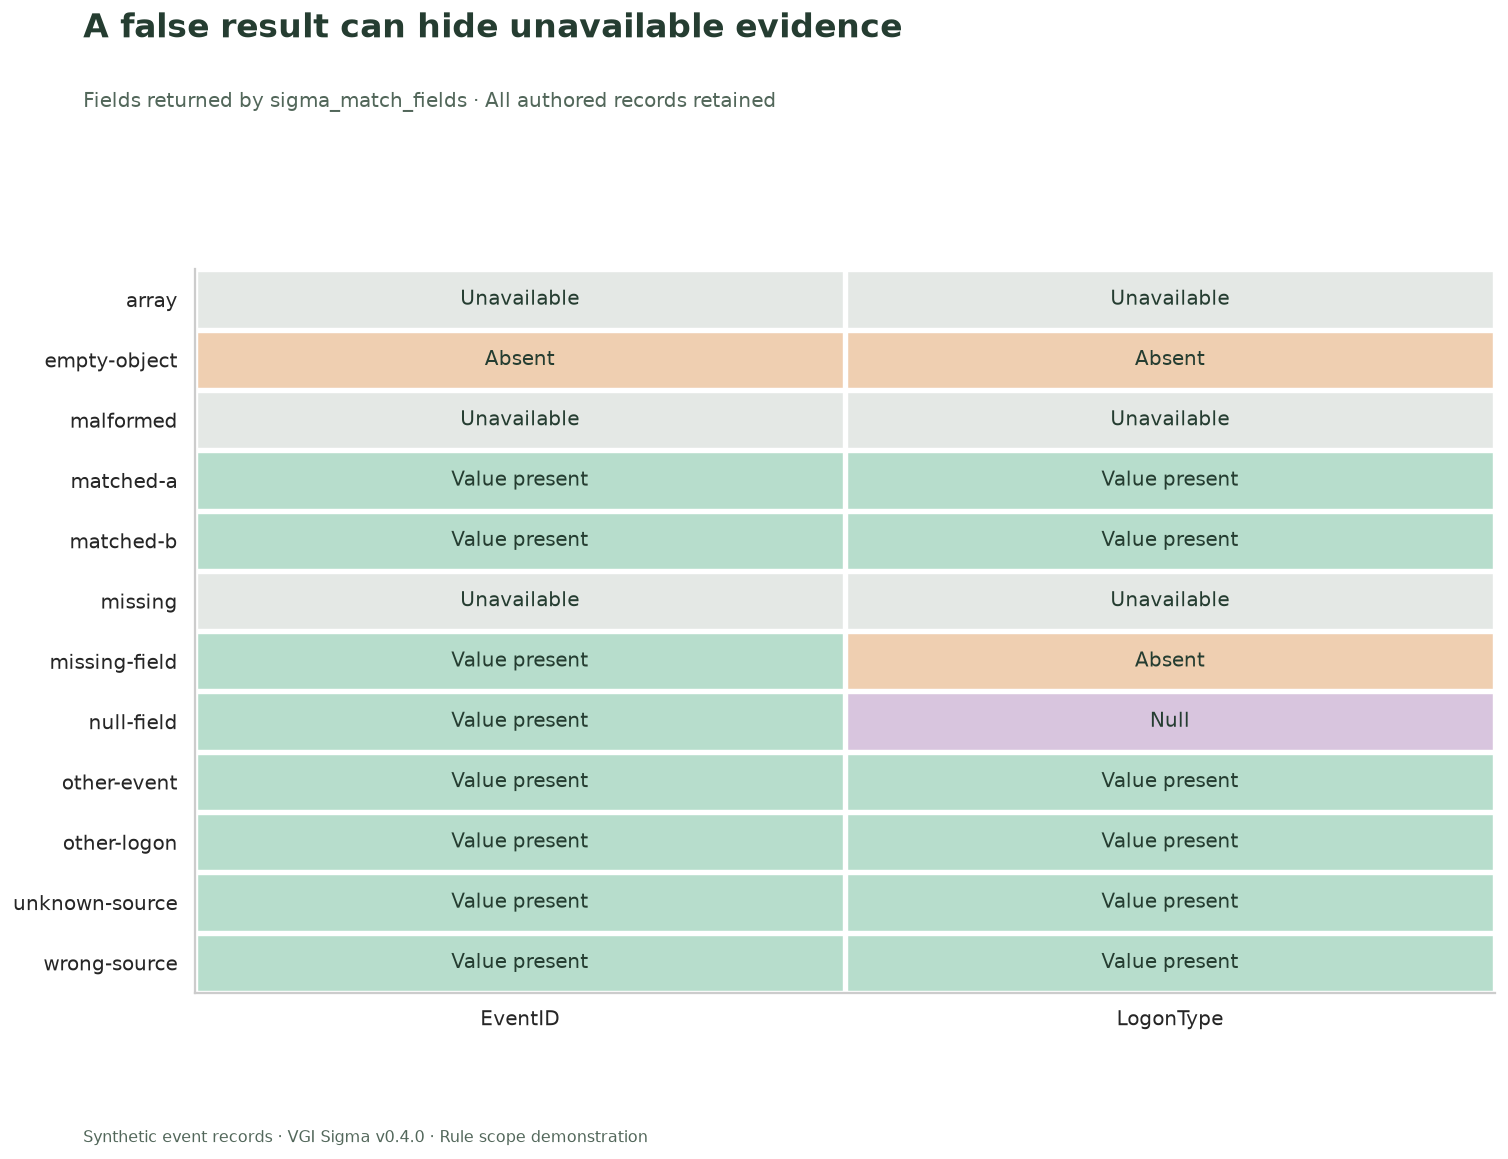

The coverage grid preserves **12 records × 2 referenced fields**. Absent and null LogonType values are different input states. Neither satisfies this rule’s positive numeric comparison, while malformed, non-object and missing inputs have no usable field evidence.

In [9]:
matrix = coverage.pivot(index="event_id", columns="field", values="field_state")
states = ["Unavailable", "Absent", "Null", "Value present"]
values = np.array(
    [[states.index(v) for v in row] for row in matrix.itertuples(index=False, name=None)]
)
fig, ax = plt.subplots(figsize=(12, 9.1))
ax.imshow(
    values,
    cmap=ListedColormap(["#e4e8e5", "#efcfb1", "#d8c5de", "#b7ddcc"]),
    vmin=0,
    vmax=3,
    aspect="auto",
)
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set_yticks(range(len(matrix)), matrix.index)
ax.grid(False)
ax.set_xticks(np.arange(-0.5, len(matrix.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(matrix), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)
for y, row in enumerate(values):
    for x, v in enumerate(row):
        ax.text(x, y, states[v], ha="center", va="center", fontsize=11, color="#253d31")
finish(
    fig,
    "A false result can hide unavailable evidence",
    "Fields returned by sigma_match_fields · All authored records retained",
    "01_field_availability.png",
    bottom=0.10,
)
prose(
    f"The coverage grid preserves **{len(matrix)} records × {len(matrix.columns)} referenced fields**. "
    "Absent and null LogonType values are different input states. Neither satisfies this rule’s positive numeric comparison, while malformed, non-object and missing inputs have no usable field evidence."
)

## Keep raw condition results separate from the selected population

Run the real scalar over every event, including malformed and missing inputs, and
join the parsed metadata to the outer source labels. A wrong label yields false
scope agreement; an absent label yields unknown agreement. The default requires
known agreement on both labels.

The two in-scope positive fixtures, the wrong-source fixture and the unknown-source
fixture contain identical event JSON. All four satisfy the condition. Only the
source labels change whether they enter the scoped review. In a real ingestion
pipeline those labels need trustworthy provenance; this comparison does not verify it.

In [10]:
%%sql
CREATE TABLE raw_results AS SELECT i.*,sigma.main.sigma_match(i.event_json,r.rule_yaml) AS raw_match,
 i.source_product=m.product AND i.source_service=m.service AS scope_match
FROM input_quality i CROSS JOIN rule_validation r CROSS JOIN rule_info m
WHERE r.rule_id='selected' AND r.compiles;
CREATE TABLE decisions AS SELECT *,coalesce(raw_match,false)
 AND (NOT {{ ENFORCE_LOGSOURCE }} OR coalesce(scope_match,false)) AS selected
FROM raw_results;
CREATE TABLE audit AS SELECT *,CASE
 WHEN input_kind='Missing input' THEN 'Missing input'
 WHEN input_kind<>'Object' THEN 'Invalid event shape'
 WHEN selected THEN 'Selected match'
 WHEN raw_match THEN 'Match withheld by source scope'
 ELSE 'Object, no condition match' END AS review_state
FROM decisions;
SELECT event_id,input_kind,source_product,source_service,scope_match,raw_match,selected,review_state
FROM audit ORDER BY event_id;

,event_id,input_kind,source_product,source_service,scope_match,raw_match,selected,review_state
0,array,Non-object JSON,windows,security,True,False,False,Invalid event shape
1,empty-object,Object,windows,security,True,False,False,"Object, no condition match"
2,malformed,Malformed JSON,windows,security,True,False,False,Invalid event shape
3,matched-a,Object,windows,security,True,True,True,Selected match
4,matched-b,Object,windows,security,True,True,True,Selected match
5,missing,Missing input,windows,security,True,<NA>,False,Missing input
6,missing-field,Object,windows,security,True,False,False,"Object, no condition match"
7,null-field,Object,windows,security,True,False,False,"Object, no condition match"
8,other-event,Object,windows,security,True,False,False,"Object, no condition match"
9,other-logon,Object,windows,security,True,False,False,"Object, no condition match"


In [11]:
%%sql summary <<
SELECT s.review_state,count(a.event_id) AS records FROM (VALUES
 (1,'Selected match'),(2,'Match withheld by source scope'),(3,'Object, no condition match'),
 (4,'Invalid event shape'),(5,'Missing input')
) AS s(sort_order,review_state)
LEFT JOIN audit a USING(review_state)
GROUP BY s.sort_order,s.review_state ORDER BY s.sort_order;

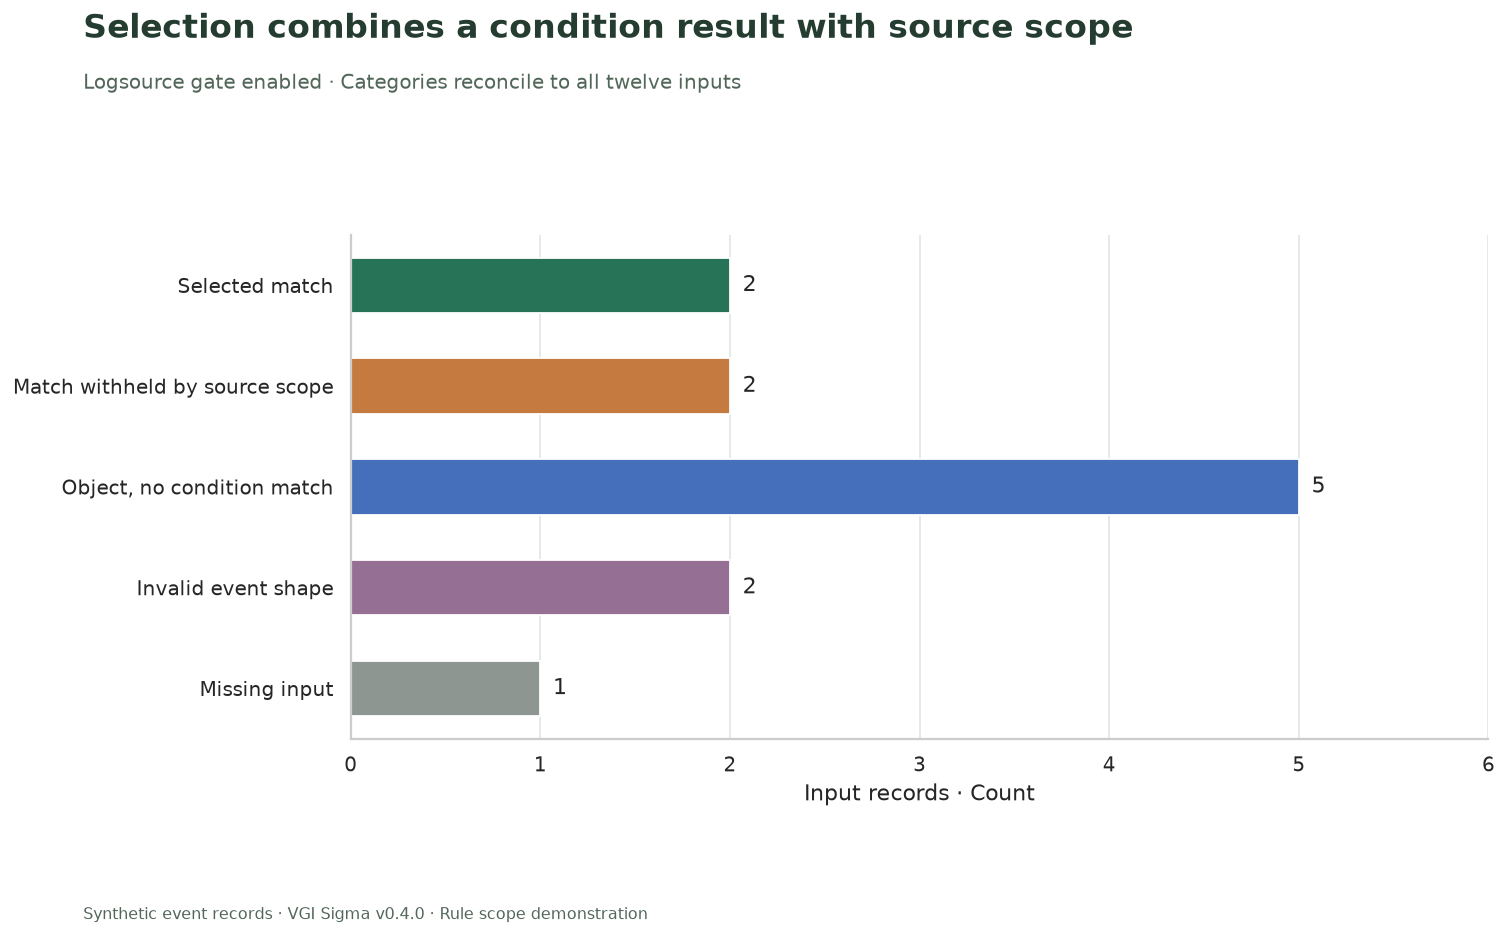

**2 condition matches are selected** and **2 are withheld by source scope**. Invalid event shape and missing input remain separate from valid-object non-matches. The selected count is a review population, not an incident count.

,review_state,records
0,Selected match,2
1,Match withheld by source scope,2
2,"Object, no condition match",5
3,Invalid event shape,2
4,Missing input,1


In [12]:
fig, ax = plt.subplots(figsize=(12, 7.3))
colors = ["#267358", "#c57b40", "#456fba", "#956f94", "#8d9690"]
bars = ax.barh(summary.review_state, summary.records, color=colors, height=0.55)
ax.bar_label(bars, padding=7, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, max(1, summary.records.max()) * 1.2)
ax.set_xlabel("Input records · Count")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Selection combines a condition result with source scope",
    f"Logsource gate {'enabled' if ENFORCE_LOGSOURCE else 'disabled'} · Categories reconcile to all twelve inputs",
    "02_review_population.png",
    bottom=0.12,
)
selected = int(summary.loc[summary.review_state == "Selected match", "records"].iloc[0])
withheld = int(
    summary.loc[summary.review_state == "Match withheld by source scope", "records"].iloc[0]
)
prose(
    f"**{selected} condition matches are selected** and **{withheld} are withheld by source scope**. "
    "Invalid event shape and missing input remain separate from valid-object non-matches. The selected count is a review population, not an incident count."
)
display(summary)

## Verify scope, missingness and reconciliation

The assertions check the pinned fixture and worker behavior, including false results
for malformed or non-object events and NULL for absent input. They also show that
turning off scope selection does not repair field availability or change the raw
condition results.

In [13]:
%%sql checks <<
SELECT 'All twelve authored records survive' AS check_name,
 (SELECT count(*)=12 AND count(DISTINCT event_id)=12 FROM audit) AS passed
UNION ALL SELECT 'Only the selected rule compiles',
 (SELECT count(*) FILTER(WHERE compiles)=1 FROM rule_validation)
 AND (SELECT compiles FROM rule_validation WHERE rule_id='selected')
UNION ALL SELECT 'Rule metadata declares the intended source',
 (SELECT product='windows' AND service='security' FROM rule_info)
UNION ALL SELECT 'Field introspection identifies exactly the two comparisons',
 (SELECT count(*)=2 AND bool_and(field IN ('EventID','LogonType')) FROM required_fields)
UNION ALL SELECT 'Coverage is one row per input and referenced field',
 (SELECT count(*)=24 FROM field_coverage)
UNION ALL SELECT 'Absent and explicitly null field states differ',
 (SELECT field_state='Absent' FROM field_coverage WHERE event_id='missing-field' AND field='LogonType')
 AND (SELECT field_state='Null' FROM field_coverage WHERE event_id='null-field' AND field='LogonType')
UNION ALL SELECT 'Missing event preserves NULL raw result',
 (SELECT raw_match IS NULL AND NOT selected FROM audit WHERE event_id='missing')
UNION ALL SELECT 'Malformed and non-object inputs return false but retain quality states',
 (SELECT count(*)=2 AND bool_and(NOT raw_match AND review_state='Invalid event shape') FROM audit WHERE event_id IN ('array','malformed'))
UNION ALL SELECT 'All four identical condition payloads match regardless of labels',
 (SELECT count(*)=4 AND count(DISTINCT event_json)=1 AND bool_and(raw_match)
 FROM audit WHERE event_id IN ('matched-a','matched-b','wrong-source','unknown-source'))
UNION ALL SELECT 'Absent source labels retain unknown scope agreement',
 (SELECT scope_match IS NULL FROM audit WHERE event_id='unknown-source')
UNION ALL SELECT 'Selected match count follows only the scope parameter',
 (SELECT count(*) FILTER(WHERE selected)=CASE WHEN {{ ENFORCE_LOGSOURCE }} THEN 2 ELSE 4 END FROM audit)
UNION ALL SELECT 'Selection never creates a condition match',
 NOT EXISTS(SELECT 1 FROM audit WHERE selected AND NOT coalesce(raw_match,false));

In [14]:
display(checks)
assert checks.passed.fillna(False).all(), checks.loc[~checks.passed.fillna(False)]
assert int(summary.records.sum()) == con.execute("SELECT count(*) FROM inputs").fetchone()[0]
assert (
    selected + withheld == con.execute("SELECT count(*) FROM audit WHERE raw_match").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and two chart reconciliations passed.** The result preserves event quality, field coverage, condition evaluation and selected scope as separate evidence."
)

,check_name,passed
0,All twelve authored records survive,True
1,Only the selected rule compiles,True
2,Rule metadata declares the intended source,True
3,Field introspection identifies exactly the two...,True
4,Coverage is one row per input and referenced f...,True
5,Absent and explicitly null field states differ,True
6,Missing event preserves NULL raw result,True
7,Malformed and non-object inputs return false b...,True
8,All four identical condition payloads match re...,True
9,Absent source labels retain unknown scope agre...,True


**12 SQL checks and two chart reconciliations passed.** The result preserves event quality, field coverage, condition evaluation and selected scope as separate evidence.

## Experiment: remove source gating

Change **`ENFORCE_LOGSOURCE=True` to `False`**, restart and run all. Predict that
selected matches rise while the field-availability chart and raw matches remain
unchanged. Inspect `wrong-source` and `unknown-source`: they have the same matching
event fields as the in-scope fixtures but different source evidence.

This experiment broadens query scope. It does not fix malformed JSON, fill missing
fields, verify provenance, or improve the rule's detection quality. Restore **`True`**
to return to the saved source-scoped review.

In [15]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)